A - LINEAR TREND ESTIMATION

Linear Trend Equation
y = 11134.30 + (32.83)X


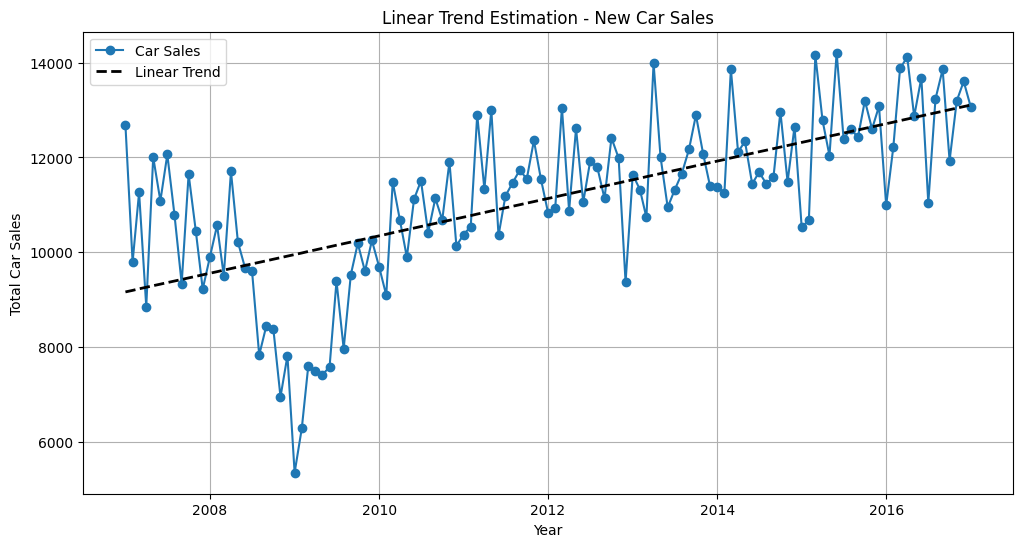

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("New Car Sales by Make.csv")

df["Date"] = pd.to_datetime(
    dict(year=df["Year"], month=df["Month"], day=1)
)

df = df.groupby("Date")["Quantity"].sum().reset_index()
df = df.sort_values("Date")

period = df["Date"]
sales = df["Quantity"].tolist()

n = len(sales)

X = [i - n//2 for i in range(n)]

x2 = [i**2 for i in X]
xy = [i*j for i, j in zip(X, sales)]

b = (n*sum(xy) - sum(sales)*sum(X)) / (n*sum(x2) - sum(X)**2)
a = (sum(sales) - b*sum(X)) / n

linear_trend = [a + b*X[i] for i in range(n)]

print("Linear Trend Equation")
print(f"y = {a:.2f} + ({b:.2f})X")

plt.figure(figsize=(12,6))
plt.plot(period, sales, marker='o', label="Car Sales")
plt.plot(period, linear_trend, 'k--', linewidth=2, label="Linear Trend")

plt.title("Linear Trend Estimation - New Car Sales")
plt.xlabel("Year")
plt.ylabel("Total Car Sales")
plt.legend()
plt.grid(True)
plt.show()


B- POLYNOMIAL TREND ESTIMATION



Polynomial Trend Equation
y = 10938.33 + (32.83)X + (0.16)X²


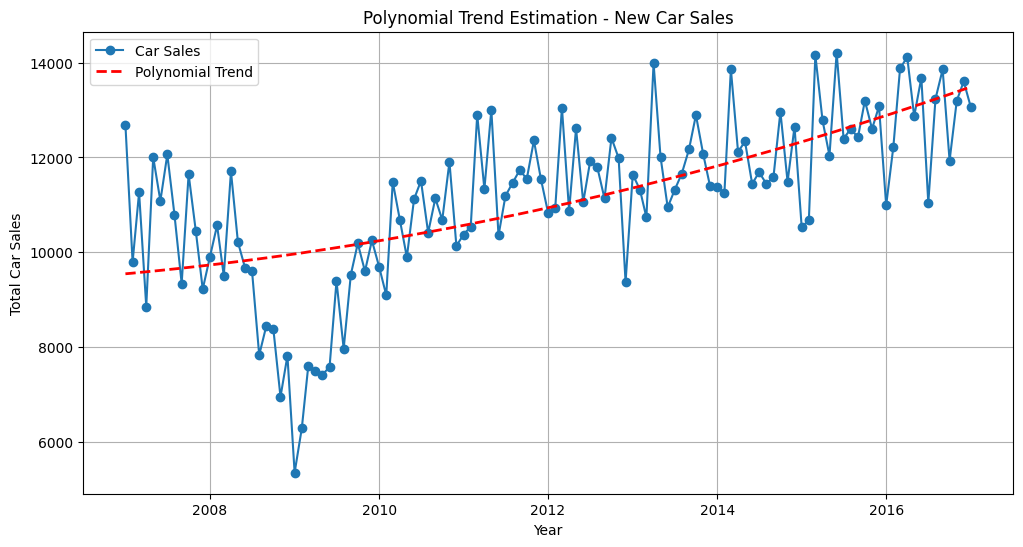

In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("New Car Sales by Make.csv")

df["Date"] = pd.to_datetime(
    dict(year=df["Year"], month=df["Month"], day=1)
)

df = df.groupby("Date")["Quantity"].sum().reset_index()
df = df.sort_values("Date")

period = df["Date"]
sales = df["Quantity"].tolist()

n = len(sales)

X = [i - n//2 for i in range(n)]

x2 = [i**2 for i in X]
xy = [i*j for i, j in zip(X, sales)]

x3 = [i**3 for i in X]
x4 = [i**4 for i in X]
x2y = [i*j for i, j in zip(x2, sales)]

coeff = [
    [n, sum(X), sum(x2)],
    [sum(X), sum(x2), sum(x3)],
    [sum(x2), sum(x3), sum(x4)]
]

Y = [
    sum(sales),
    sum(xy),
    sum(x2y)
]

A = np.array(coeff)
B = np.array(Y)

a_poly, b_poly, c_poly = np.linalg.solve(A, B)

poly_trend = [
    a_poly + b_poly*X[i] + c_poly*(X[i]**2)
    for i in range(n)
]

print("Polynomial Trend Equation")
print(f"y = {a_poly:.2f} + ({b_poly:.2f})X + ({c_poly:.2f})X²")

plt.figure(figsize=(12,6))
plt.plot(period, sales, marker='o', label="Car Sales")
plt.plot(period, poly_trend, 'r--', linewidth=2, label="Polynomial Trend")

plt.title("Polynomial Trend Estimation - New Car Sales")
plt.xlabel("Year")
plt.ylabel("Total Car Sales")
plt.legend()
plt.grid(True)
plt.show()
